# 07 · dataset_500 ile Eğitim ve Değerlendirme

`p_radar_sim/rd_dataset/gen_rd_dataset.py` ile üretilen **500 target + 500 notarget** Range-Doppler haritası
(`data/dataset_500`). Her harita 1 dakikalık bir ses dosyasının 0.5 s'lik parçasından FM pasif radar simülasyonuyla
üretildi (direkt yol + clutter + ECA bastırma + gürültü; `target` haritalarına bilinen gecikme/Doppler ile yankı eklendi).
Kaynaklar: `data/dataset_500/kaynaklar.csv`.

Akış: ses dosyası bazlı train/val/test bölmesi → tek kanallı CNN eğitimi (model seçimi yalnızca val) →
test bölümünde bağımsız değerlendirme → tespit başarımının çıkış SNR'ına göre değişimi.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "passive_radar").is_dir())
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

In [2]:
import json
from dataclasses import asdict, replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from passive_radar.config import CLASS_NAMES, ProjectConfig
from passive_radar.data.dataset import RangeDopplerDataset, make_data_loader
from passive_radar.data.indexing import SPLIT_NAMES, assert_no_group_leakage, records_in_split, save_split_csv, split_by_source
from passive_radar.data.rd_dataset import load_rd_dataset_config, load_rd_samples, samples_to_records
from passive_radar.evaluation.metrics import collect_predictions, metrics_from_predictions
from passive_radar.evaluation.plots import plot_confusion_matrix, plot_rd_maps, plot_training_history
from passive_radar.models.checkpoint import load_checkpoint
from passive_radar.models.cnn import RangeDopplerCNN, count_trainable_parameters
from passive_radar.training.runtime import resolve_device, set_seed
from passive_radar.training.trainer import Trainer

config = ProjectConfig.default(PROJECT_ROOT)
paths = config.paths
data_dir = paths.rd_dataset_500_dir
out_dir = paths.rd_dataset_500_outputs_dir
(out_dir / "figures").mkdir(parents=True, exist_ok=True)

sim = load_rd_dataset_config(data_dir)
max_range_km = sim["r_max"] * sim["range_cell_m"] / 1e3
max_doppler_hz = sim["fD_max"]

rd_config = config.rd_map
model_config = replace(config.model, in_channels=rd_config.num_channels, pooled_size=(2, 2), global_pool="max")
training_config = replace(config.training, batch_size=32, learning_rate=1e-3, max_epochs=30, early_stopping_patience=5)
for name, section in (("rd_map", rd_config), ("model", model_config), ("training", training_config)):
    print(f"{name}: {asdict(section)}")
print(f"map: {sim['n_doppler']} Doppler x {sim['r_max']} range | {max_range_km:.1f} km, ±{max_doppler_hz:.0f} Hz")

rd_map: {'dynamic_range_db': 40.0}
model: {'in_channels': 1, 'num_classes': 2, 'conv_channels': (16, 32, 64, 128), 'kernel_size': 3, 'pooled_size': (2, 2), 'global_pool': 'max', 'hidden_units': 128, 'dropout': 0.4}
training: {'batch_size': 32, 'learning_rate': 0.001, 'weight_decay': 0.0, 'max_epochs': 30, 'early_stopping_patience': 5, 'min_delta': 0.0001, 'num_workers': 0, 'device': 'auto', 'seed': 42, 'cache_images': True}
map: 371 Doppler x 73 range | 99.3 km, ±185 Hz


## 1. Veri ve ses dosyası bazlı bölme

In [3]:
samples = load_rd_samples(data_dir)
meta = pd.DataFrame([s.__dict__ for s in samples])
meta["path"] = [str(s.path(data_dir)) for s in samples]

# Aynı 1 dakikalık ses dosyasından gelen tüm haritalar aynı bölmede kalır (sızıntı yok).
# Daha katı test için group_by="source_group" (bütün ses klasörü dışarıda tutulur).
records = samples_to_records(samples, data_dir, group_by="source_file")
split_config = replace(config.split, max_holdout_group_fraction=0.2)
assigned = split_by_source(records, split_config)
assert_no_group_leakage(assigned)
save_split_csv(assigned, out_dir / "splits.csv", relative_to=paths.project_root)
split_of = {str(r.path): r.split for r in assigned}
meta["split"] = meta["path"].map(split_of)

pd.DataFrame([
    {"split": s, "maps": len(rs), "target": sum(r.label == 1 for r in rs),
     "audio_files": len({r.source_id for r in rs}),
     "audio_folders": meta.loc[meta.split == s, "source_group"].nunique()}
    for s in SPLIT_NAMES for rs in [records_in_split(assigned, s)]
])

,split,maps,target,audio_files,audio_folders
0,train,715,361,90,14
1,val,141,72,18,13
2,test,144,67,18,13


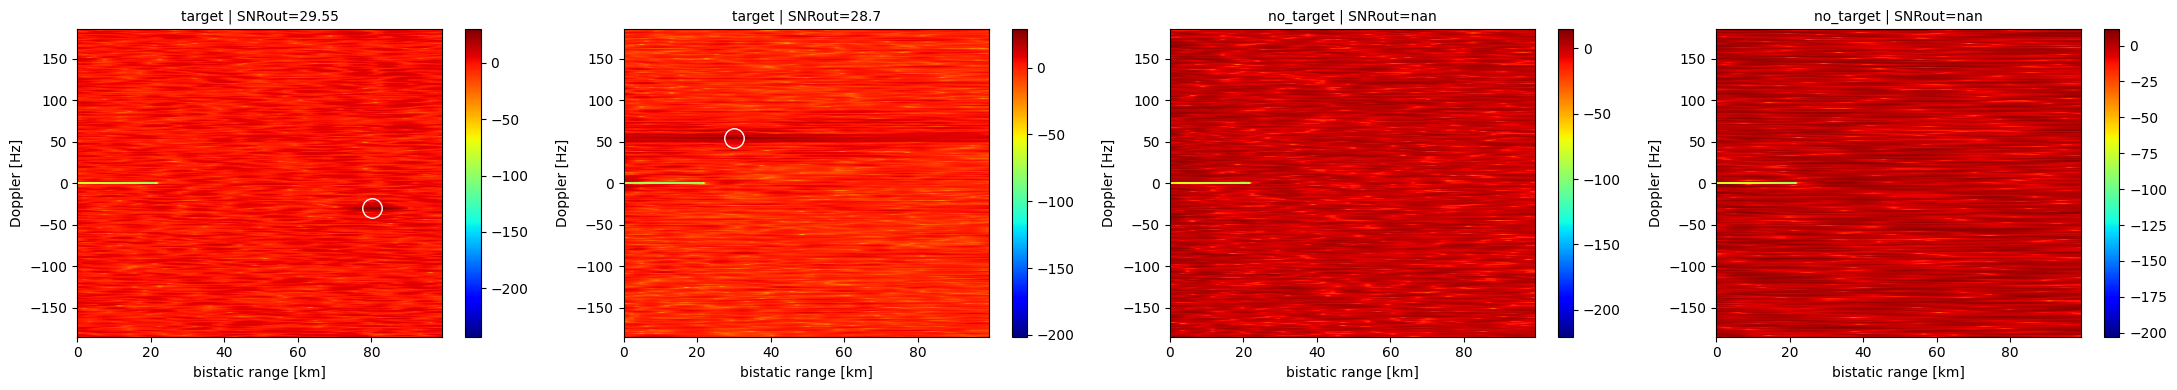

In [4]:
# Örnek haritalar (npy satır 0 = +Doppler; plot_rd_maps origin='lower' kullandığı için ters çevrilir)
show = pd.concat([meta[meta.label == 1].sort_values("snr_out_db", ascending=False).head(2),
                  meta[meta.label == 0].head(2)])
plot_rd_maps([np.flipud(np.load(p).astype(np.float32)) for p in show["path"]],
             [f"{CLASS_NAMES[l]} | SNRout={s}" for l, s in show[["label", "snr_out_db"]].itertuples(index=False)],
             max_range_km, max_doppler_hz,
             markers=[(r, d) if l == 1 else None for l, r, d in
                      show[["label", "bistatic_range_km", "doppler_hz"]].itertuples(index=False)],
             save_path=out_dir / "figures" / "examples.png")
plt.show()

## 2. Eğitim (early stopping, en iyi model val kaybına göre)

device: mps | parameters: 163,314
epoch 01 | train_loss 0.7994 | val_loss 0.7282 | val_acc 0.489 | val_f1 0.000 *best*
epoch 02 | train_loss 0.7250 | val_loss 0.7033 | val_acc 0.489 | val_f1 0.000 *best*
epoch 03 | train_loss 0.6816 | val_loss 0.6905 | val_acc 0.511 | val_f1 0.676 *best*
epoch 04 | train_loss 0.6788 | val_loss 0.6718 | val_acc 0.582 | val_f1 0.459 *best*
epoch 05 | train_loss 0.6561 | val_loss 0.6600 | val_acc 0.582 | val_f1 0.379 *best*
epoch 06 | train_loss 0.6425 | val_loss 0.6366 | val_acc 0.638 | val_f1 0.679 *best*
epoch 07 | train_loss 0.6064 | val_loss 0.6018 | val_acc 0.638 | val_f1 0.605 *best*
epoch 08 | train_loss 0.6057 | val_loss 0.6147 | val_acc 0.631 | val_f1 0.519
epoch 09 | train_loss 0.5652 | val_loss 0.6276 | val_acc 0.596 | val_f1 0.698
epoch 10 | train_loss 0.5456 | val_loss 0.6515 | val_acc 0.638 | val_f1 0.571
epoch 11 | train_loss 0.5261 | val_loss 0.6443 | val_acc 0.603 | val_f1 0.696
epoch 12 | train_loss 0.4671 | val_loss 0.8513 | val_acc 0.

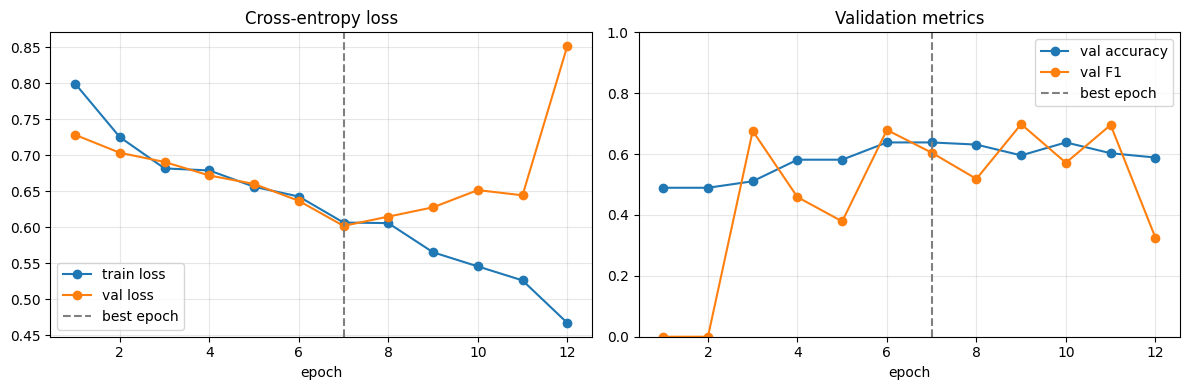

In [5]:
loaders = {
    split: make_data_loader(
        RangeDopplerDataset(records_in_split(assigned, split), rd_config, cache_images=True),
        training_config.batch_size, shuffle=(split == "train"), seed=training_config.seed)
    for split in SPLIT_NAMES
}
set_seed(training_config.seed)
device = resolve_device(training_config.device)
model = RangeDopplerCNN(model_config)
print("device:", device, "| parameters:", f"{count_trainable_parameters(model):,}")

trainer = Trainer(model, training_config, device, paths.rd_dataset_500_checkpoint_path, CLASS_NAMES, rd_config)
history = trainer.fit(loaders["train"], loaders["val"])
history.save_json(out_dir / "training_history.json")
plot_training_history(history, save_path=out_dir / "figures" / "training_history.png")
plt.show()

## 3. Test bölümünde bağımsız değerlendirme

In [6]:
checkpoint = load_checkpoint(paths.rd_dataset_500_checkpoint_path, device=device)
results = {}
for split in ("val", "test"):
    predictions = collect_predictions(checkpoint.model, loaders[split], device)
    results[split] = (predictions, metrics_from_predictions(predictions))
(out_dir / "test_metrics.json").write_text(json.dumps({s: m for s, (_, m) in results.items()}, indent=2))
pd.DataFrame({s: {k: v for k, v in m.items() if k != "confusion_matrix"} for s, (_, m) in results.items()}).T

,accuracy,precision,recall,f1,support,roc_auc
val,0.638298,0.684211,0.541667,0.604651,141.0,0.704308
test,0.611111,0.575342,0.626866,0.600000,144.0,0.663501


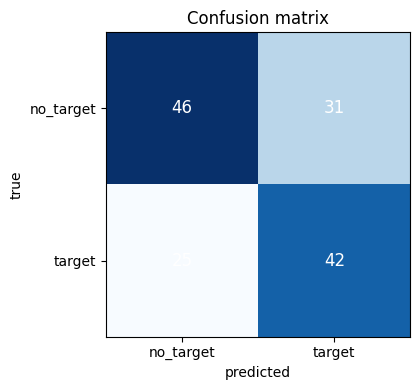

In [7]:
test_predictions, test_metrics = results["test"]
plot_confusion_matrix(test_metrics["confusion_matrix"], CLASS_NAMES,
                      save_path=out_dir / "figures" / "confusion_matrix_test.png")
plt.show()

## 4. Tespit olasılığı ve yanlış alarm — çıkış SNR'ına göre

false alarm rate (notarget -> target): 0.403
detection rate, visible targets (SNRout >= 13 dB): 0.931
detection rate, weak targets    (SNRout <  13 dB): 0.395


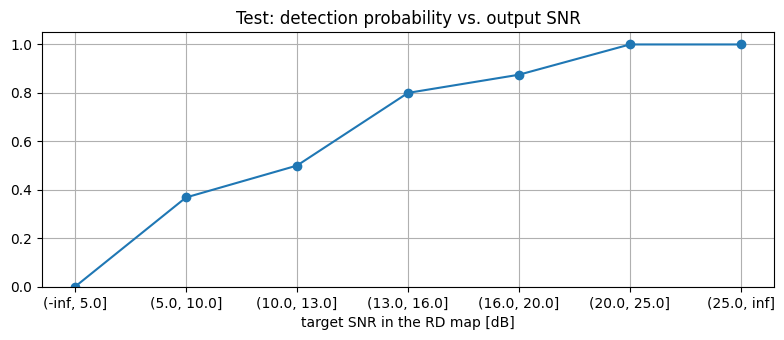

,detection_probability,maps
snr_bin,,
"(-inf, 5.0]",0.000000,3
"(5.0, 10.0]",0.368421,19
"(10.0, 13.0]",0.500000,16
"(13.0, 16.0]",0.800000,5
"(16.0, 20.0]",0.875000,8
"(20.0, 25.0]",1.000000,13
"(25.0, inf]",1.000000,3


In [8]:
test_records = records_in_split(assigned, "test")
frame = pd.DataFrame({"path": [str(r.path) for r in test_records], "true": test_predictions.y_true,
                      "pred": test_predictions.y_pred, "p_target": test_predictions.positive_probability}
                     ).merge(meta, on="path")

false_alarm_rate = (frame.loc[frame["true"] == 0, "pred"] == 1).mean()
targets = frame[frame["true"] == 1].copy()
targets["snr_bin"] = pd.cut(targets["snr_out_db"], bins=[-np.inf, 5, 10, 13, 16, 20, 25, np.inf])
pd_by_snr = targets.groupby("snr_bin", observed=True)["pred"].agg(detection_probability="mean", maps="size")
print(f"false alarm rate (notarget -> target): {false_alarm_rate:.3f}")
print(f"detection rate, visible targets (SNRout >= 13 dB): {targets.loc[targets.visible == True, 'pred'].mean():.3f}")
print(f"detection rate, weak targets    (SNRout <  13 dB): {targets.loc[targets.visible == False, 'pred'].mean():.3f}")

axis = pd_by_snr["detection_probability"].plot(marker="o", figsize=(8, 3.5), ylim=(0, 1.05), grid=True,
                                                title="Test: detection probability vs. output SNR")
axis.set_xlabel("target SNR in the RD map [dB]")
plt.tight_layout()
plt.savefig(out_dir / "figures" / "detection_vs_snr.png", dpi=120)
plt.show()
pd_by_snr

In [9]:
# Ses klasörüne göre doğruluk (hangi içerik türü zor?)
frame.assign(correct=frame.true == frame.pred).groupby("source_group")["correct"].agg(["mean", "size"]).sort_values("mean")

,mean,size
source_group,,
"90min of PURE RAW RACING SOUNDS ¦ F1, Group C, GT1, GT2, GT3, Rally, DTM, Classics, ... (128kbit_AAC)",0.4375,16
"1 hour fighter jet sound (jet engine, stealth bomber, f16, f117, f117a, raptor, b2, ASMR) (128kbit_AAC)",0.5000,8
İSTEK ÜZERİNE DAHA UZUN İNCE BİR YOL ¦ DRIVE BEYOND HORIZONS ¦ BÖLÜM 3 (128kbit_AAC),0.5000,16
Nervous System Reset ¦ 75Hz + 111Hz Emotional Balance ¦ Healing Bowls ¦ Meditation & Sleep Music (128kbit_AAC),0.5000,8
RRaenee GTA 5 PLAYLİST Editimi İzliyor! (Komik Anlar) (128kbit_AAC),0.5000,8
"ADAM, Elyanna & Massari - Calling You, ZHUREK & Real Love (Isko Alvarez & Kamro Remix) (128kbit_AAC)",0.6250,16
Afro House Sunset Mix 2025 ¦ Miami Vibes (128kbit_AAC),0.6250,8
ERHAN BORAER ¦ Music Playlist 2023⁄2024⁄2025 ¦ Turkish & Deep House (128kbit_AAC),0.6250,8
ZOMBİLERİN YIKMAYA KIYAMAYACAĞI EV! ¦ 7 DAYS TO DIE ¦ S3 B4 (128kbit_AAC),0.6250,8


## 5. Hatalı sınıflandırılan örnekler

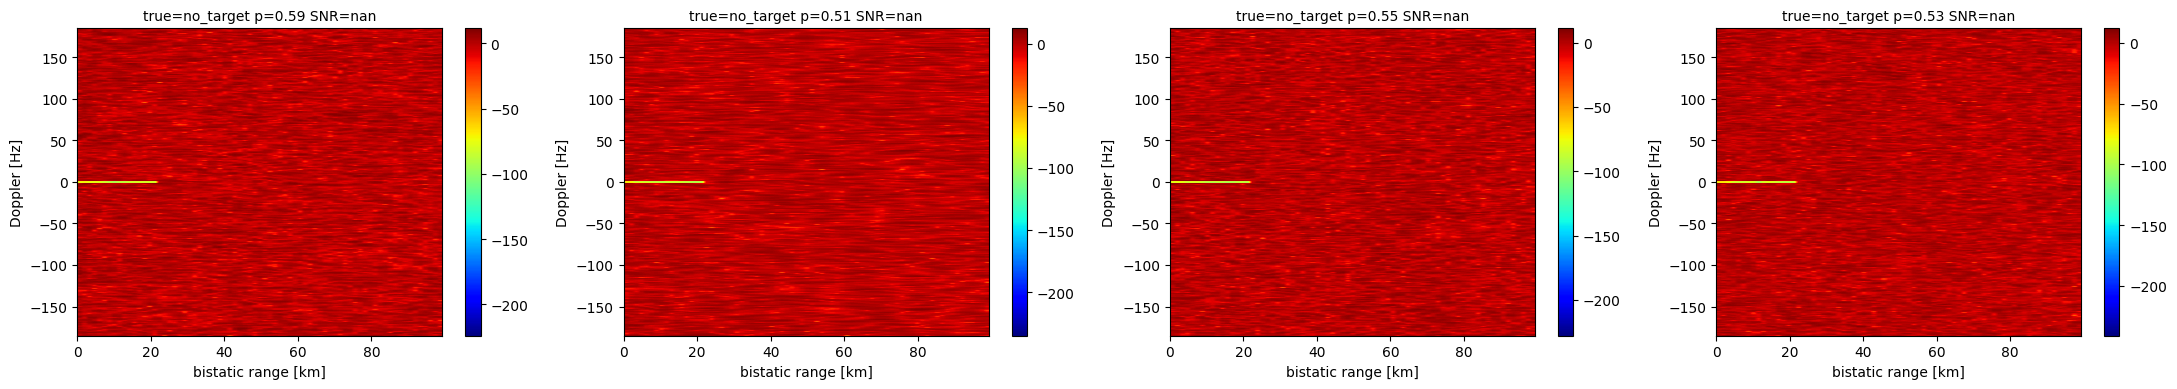

In [10]:
wrong = frame[frame["true"] != frame["pred"]].head(4)
if wrong.empty:
    print("No misclassified test maps.")
else:
    plot_rd_maps([np.flipud(np.load(p).astype(np.float32)) for p in wrong["path"]],
                 [f"true={CLASS_NAMES[t]} p={q:.2f} SNR={s}" for t, q, s in
                  wrong[["true", "p_target", "snr_out_db"]].itertuples(index=False)],
                 max_range_km, max_doppler_hz,
                 markers=[(r, d) if t == 1 else None for t, r, d in
                          wrong[["true", "bistatic_range_km", "doppler_hz"]].itertuples(index=False)],
                 save_path=out_dir / "figures" / "misclassified_test.png")
    plt.show()

## 6. Yorum ve sınırlılıklar

* Etiketler fiziksel olarak tanımlıdır (yankı eklendi / eklenmedi); kaynak ses ve zaman aralığı `kaynaklar.csv`'de.
* Hedefli haritaların bir kısmı zayıftır (`visible=0`, çıkış SNR < 13 dB); bunlarda tespit oranının düşmesi beklenir.
* Bölme ses dosyası bazındadır; aynı ses klasöründen (ör. aynı playlist) farklı dosyalar farklı bölmelerde olabilir.
  İçerik türüne genelleme için `group_by="source_group"` ile tekrar çalıştırılabilir.
* Gerçek ölçüm verisine genelleme doğrulanmamıştır.